In [ ]:
from firedrake import *
from scipy.special import j0, j1, jn_zeros
import numpy as np
import matplotlib.pyplot as plt

R = 100e-9 # radius in m
D = 2.06e-18 # diffusion coefficient, m²/s
c0 = 1.0  # initial concentration
cmax = 88.67   # surface concentration
dt = 0.1   # time step

roots = jn_zeros(0, 100)  # first 100 zeros of J_0 the first bessel function of the first kind


#analytical solution for concentration profile in a cylinder with w being the function 1-q(the normalized concentration) which we work out as a fourier series 
# expansion of the solution to the diffusion equation in cylindrical coordinates. The sum is over the first axis of the array (the roots of the Bessel function).
def analytical_concentration(x, time):
    
    x = np.array(x, dtype=float)   # allows x to be a list or NumPy array
    tau = D * time / R**2 #change of variable to dimensionless time

    w = np.zeros(len(x))

    for root in roots:
        w += (
            2 * j0(root * x)
            / (root * j1(root))
            * np.exp(-root**2 * tau)
        )

    q = 1 - w #normalized concentration
    return c0 + (cmax - c0) * q



def fem_concentration_solver(n_ele, times):
    mesh = IntervalMesh(n_ele, 1.0) # 1D mesh with n_ele elements

    V = FunctionSpace(mesh, "CG", 1) # create a function space on the mesh where CG stands for continuous Galerkin and 1 is the degree of the polynomial basis functions
    x = SpatialCoordinate(mesh)[0] # get the spatial coordinate of the mesh

    q_p = Function(V) # create a function to hold the previous concentration profile
    q = Function(V) # create a function to hold the current concentration profile
    q_p.assign(0.0) # initialize the previous concentration to 0

    bc = DirichletBC(V, 1.0, 2) # create a boundary condition that sets the concentration to 1 at the surface
    bc.apply(q_p) # apply the boundary condition to the start concentration 

    trial = TrialFunction(V) # create a trial function for the variational problem hold the function for concentration
    test = TestFunction(V) # test function for the weak form

    lhs = (
        x*trial*test/dt + (D/R**2)*x*dot(grad(trial), grad(test)) #grad represent the spatial gradient
    ) *dx # define the left-hand side integral of the variational problem
    rhs = x*q_p*test/dt*dx # likewise

    
    equation = LinearVariationalProblem(lhs, rhs,q, bcs = [bc]) #Prepares a solver for that problem. Keeping this object lets you reuse it at every time step.
    solver = LinearVariationalSolver(equation)

 
    node = np.linspace(0, 1, n_ele + 1) 
 
    #deciding which time step to keep 
    profile = {}#in dictionary because we want to store the concentration profile at different times, 
    #with the time as the key and the concentration profile as the value.
    sample_step = {round(time / dt): time for time in times}
    final_step = max(sample_step)

    #solve and capture snapshot in time 
    for i in range(1, final_step+1):
        solver.solve()# solve new concentration for each time step

        if i in sample_step:
            time = sample_step[i]
            profile[time] = (c0 + (cmax - c0) * q.dat.data_ro) #used to store the array which Firedrake calculated.

        q_p.assign(q)

    return node, profile
    


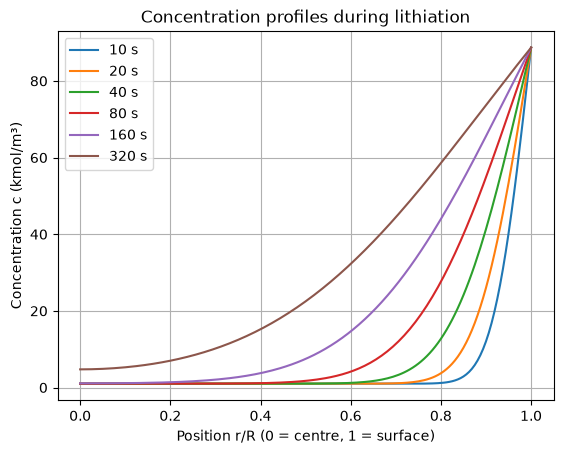

In [16]:
times_to_plot = [10, 20, 40, 80, 160, 320]
x_fem, profiles_fem = fem_concentration_solver(160, times_to_plot)

x_smooth = np.linspace(0, 1, 500)

for time in times_to_plot:
    plt.plot(x_fem, profiles_fem[time], label=f"{time} s")

plt.xlabel("Position r/R (0 = centre, 1 = surface)")
plt.ylabel("Concentration c (kmol/m³)")
plt.title("Concentration profiles during lithiation")
plt.legend()
plt.grid(True)
plt.show()

 10 elements: profile RMS error = 2.55247 kmol/m³
 20 elements: profile RMS error = 0.70847 kmol/m³
 30 elements: profile RMS error = 0.31684 kmol/m³


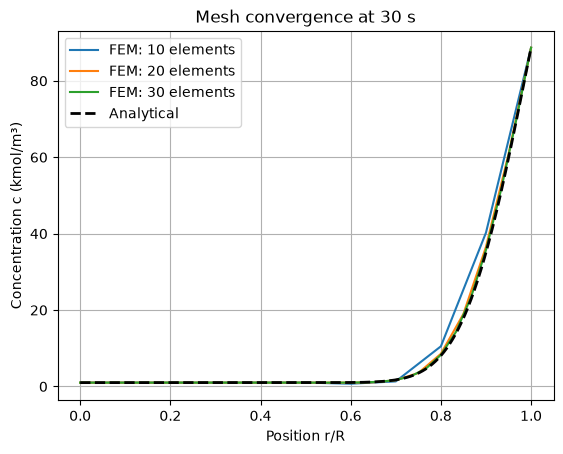

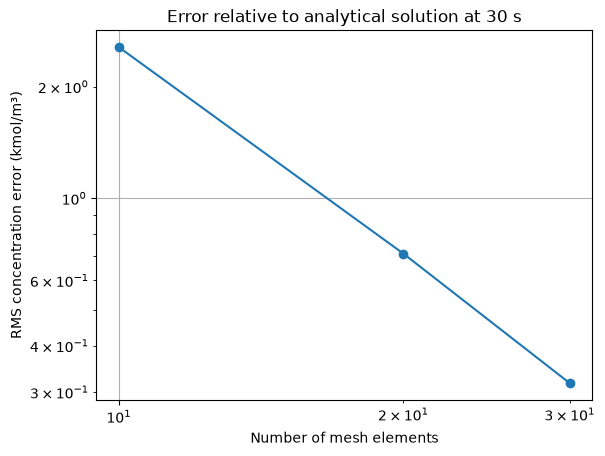

In [17]:
mesh_sizes = [10, 20, 30]
x_compare = np.linspace(0, 1, 1000)
c_analytical = analytical_concentration(x_compare, 30)

errors = []

plt.figure()

for n in mesh_sizes:
    x_nodes, profiles = fem_concentration_solver(n, [30])
    c_fem = profiles[30]

    # Compare all meshes at the same positions.
    c_on_common_grid = np.interp(x_compare, x_nodes, c_fem)
    error = np.sqrt(np.mean((c_on_common_grid - c_analytical)**2))
    errors.append(error)

    plt.plot(x_nodes, c_fem, label=f"FEM: {n} elements")
    print(f"{n:3d} elements: profile RMS error = {error:.5f} kmol/m³")

plt.plot(x_compare, c_analytical, "k--", linewidth=2,
         label="Analytical")
plt.xlabel("Position r/R")
plt.ylabel("Concentration c (kmol/m³)")
plt.title("Mesh convergence at 30 s")
plt.legend()
plt.grid(True)
plt.show()

plt.figure()
plt.loglog(mesh_sizes, errors, "o-") #log-log plot for mesh convergence is in general better suited here.
plt.xlabel("Number of mesh elements")
plt.ylabel("RMS concentration error (kmol/m³)")
plt.title("Error relative to analytical solution at 30 s")
plt.grid(True)
plt.show()